In [1]:
pip install textblob wordcloud matplotlib

In [2]:
pip install tensorflow numpy

In [3]:
import re
import nltk
import numpy as np

from nltk import pos_tag, word_tokenize
from nltk.tokenize import sent_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [4]:
text = """Hello , My Name is Rajat Sharma . How are you ? What are you Doing ?
I am fine. I am Computer Science Engineer . What about you ?"""

text = text.lower()
clean_text = re.sub(r'[^\w\s]', '',text)
print("Cleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:", words)
print("\nSentence Tokens:", sentences)

print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(clean_text))

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
print("\nAfter Stopword Removal:", filtered_words)

frequency = FreqDist(filtered_words)
print("\nWord Frequencies:", frequency.most_common())


Cleaned Text:
 hello  my name is rajat sharma  how are you  what are you doing 
i am fine i am computer science engineer  what about you 

Word Tokens: ['hello', 'my', 'name', 'is', 'rajat', 'sharma', 'how', 'are', 'you', 'what', 'are', 'you', 'doing', 'i', 'am', 'fine', 'i', 'am', 'computer', 'science', 'engineer', 'what', 'about', 'you']

Sentence Tokens: ['hello , my name is rajat sharma .', 'how are you ?', 'what are you doing ?', 'i am fine.', 'i am computer science engineer .', 'what about you ?']

Using split(): ['hello', 'my', 'name', 'is', 'rajat', 'sharma', 'how', 'are', 'you', 'what', 'are', 'you', 'doing', 'i', 'am', 'fine', 'i', 'am', 'computer', 'science', 'engineer', 'what', 'about', 'you']

Using word_tokenize(): ['hello', 'my', 'name', 'is', 'rajat', 'sharma', 'how', 'are', 'you', 'what', 'are', 'you', 'doing', 'i', 'am', 'fine', 'i', 'am', 'computer', 'science', 'engineer', 'what', 'about', 'you']

After Stopword Removal: ['hello', 'name', 'rajat', 'sharma', 'fine', '

In [5]:
text = """Artificial Intelligence is one of my favorite topics in technology.
It allows computers to learn from data and solve complex problems.
AI is used in healthcare, education, robotics, and many other fields.
Machine learning helps systems improve their performance through experience.
I believe AI will make our lives easier and more productive.
Learning about AI inspires me to explore new technologies."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in filtered_words]

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

tagged_words = pos_tag(filtered_words)
lemmatized = [
    lemmatizer.lemmatize(word, get_wordnet_pos(tag))
    for word, tag in tagged_words
]

print("Alphabetic Words:", words)
print("After Stopword Removal:", filtered_words)
print("Stemmed Words:", stemmed)
print("Lemmatized Words:", lemmatized)


Alphabetic Words: ['artificial', 'intelligence', 'is', 'one', 'of', 'my', 'favorite', 'topics', 'in', 'technology', 'it', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'robotics', 'and', 'many', 'other', 'fields', 'machine', 'learning', 'helps', 'systems', 'improve', 'their', 'performance', 'through', 'experience', 'i', 'believe', 'ai', 'will', 'make', 'our', 'lives', 'easier', 'and', 'more', 'productive', 'learning', 'about', 'ai', 'inspires', 'me', 'to', 'explore', 'new', 'technologies']
After Stopword Removal: ['artificial', 'intelligence', 'one', 'favorite', 'topics', 'technology', 'allows', 'computers', 'learn', 'data', 'solve', 'complex', 'problems', 'ai', 'used', 'healthcare', 'education', 'robotics', 'many', 'fields', 'machine', 'learning', 'helps', 'systems', 'improve', 'performance', 'experience', 'believe', 'ai', 'make', 'lives', 'easier', 'productive', 'learning', 'ai', 'insp

In [6]:
texts = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Machine learning improves artificial intelligence systems.",
    "Blockchain provides secure and transparent digital transactions."
]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(texts)

print("Bag of Words Vocabulary:")
print(bow_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

features = tfidf_vectorizer.get_feature_names_out()
scores = tfidf_matrix.toarray()

print("\nTF-IDF Scores:")
print(tfidf_matrix.toarray())

for i, text in enumerate(texts):
    top_indices = scores[i].argsort()[::-1][:3]
    keywords = [(features[j], round(scores[i][j], 3))
                for j in top_indices]
    print(f"\nText {i + 1}: {text}")
    print("Top 3 Keywords:", keywords)


Bag of Words Vocabulary:
['and' 'artificial' 'blockchain' 'computers' 'digital' 'helps' 'improves'
 'intelligence' 'learn' 'learning' 'machine' 'problems' 'provides'
 'secure' 'solve' 'systems' 'transactions' 'transparent']

Bag of Words Matrix:
[[1 1 0 1 0 1 0 1 1 0 0 1 0 0 1 0 0 0]
 [0 1 0 0 0 0 1 1 0 1 1 0 0 0 0 1 0 0]
 [1 0 1 0 1 0 0 0 0 0 0 0 1 1 0 0 1 1]]

TF-IDF Scores:
[[0.30650422 0.         0.40301621 0.         0.40301621 0.
  0.30650422 0.40301621 0.         0.         0.40301621 0.
  0.         0.40301621 0.         0.         0.        ]
 [0.3349067  0.         0.         0.         0.         0.44036207
  0.3349067  0.         0.44036207 0.44036207 0.         0.
  0.         0.         0.44036207 0.         0.        ]
 [0.         0.40824829 0.         0.40824829 0.         0.
  0.         0.         0.         0.         0.         0.40824829
  0.40824829 0.         0.         0.40824829 0.40824829]]

Text 1: Artificial intelligence helps computers learn and solve prob

In [7]:
text1 = """
Artificial intelligence enables computers to learn from data.
AI is used in healthcare, education, and robotics.
Machine learning helps computers make predictions.
AI automates tasks and improves decision making.
"""

text2 = """
Blockchain is a secure digital record system.
It stores transactions across a distributed network.
Blockchain improves transparency and data security.
It is used in finance and digital currencies.
"""

def preprocess(text):
    text = text.lower()
    words = re.findall(r'\b[a-z]+\b', text)
    return words

words1 = preprocess(text1)
words2 = preprocess(text2)

print("Text 1 Tokens:", words1)
print("Text 2 Tokens:", words2)

set1 = set(words1)
set2 = set(words2)

jaccard = len(set1 & set2) / len(set1 | set2)
print("\nJaccard Similarity:", round(jaccard, 3))

vectorizer = TfidfVectorizer()
matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(matrix[0:1], matrix[1:2])[0][0]
print("Cosine Similarity:", round(cosine, 3))


Text 1 Tokens: ['artificial', 'intelligence', 'enables', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'robotics', 'machine', 'learning', 'helps', 'computers', 'make', 'predictions', 'ai', 'automates', 'tasks', 'and', 'improves', 'decision', 'making']
Text 2 Tokens: ['blockchain', 'is', 'a', 'secure', 'digital', 'record', 'system', 'it', 'stores', 'transactions', 'across', 'a', 'distributed', 'network', 'blockchain', 'improves', 'transparency', 'and', 'data', 'security', 'it', 'is', 'used', 'in', 'finance', 'and', 'digital', 'currencies']

Jaccard Similarity: 0.143
Cosine Similarity: 0.167



Review: This phone is amazing and the battery life is excellent.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: I love this product because it is fast and easy to use.
Polarity: 0.378
Subjectivity: 0.678
Sentiment: Positive

Review: The camera quality is great and the design is beautiful.
Polarity: 0.825
Subjectivity: 0.875
Sentiment: Positive

Review: The product is terrible and the battery drains quickly.
Polarity: -0.333
Subjectivity: 0.75
Sentiment: Negative

Review: I am disappointed with the poor build quality.
Polarity: -0.575
Subjectivity: 0.675
Sentiment: Negative

Review: The phone is average and works as expected.
Polarity: -0.125
Subjectivity: 0.4
Sentiment: Negative


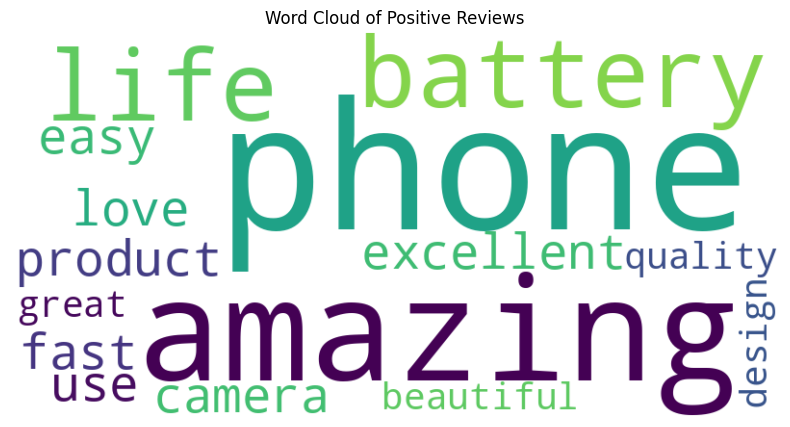

In [8]:

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This phone is amazing and the battery life is excellent.",
    "I love this product because it is fast and easy to use.",
    "The camera quality is great and the design is beautiful.",
    "The product is terrible and the battery drains quickly.",
    "I am disappointed with the poor build quality.",
    "The phone is average and works as expected."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


In [9]:
text = """
Technology is changing the world every day.
Artificial intelligence helps computers learn from data.
Machine learning allows systems to identify patterns and make predictions.
Robotics combines hardware and software to perform useful tasks.
Cloud computing provides storage and computing resources over the internet.
Students use technology to learn new skills and solve problems.
Programming teaches logical thinking and improves creativity.
Modern applications connect people and make communication easier.
Data science helps organizations understand information and make decisions.
Technology continues to create new opportunities for education and business.
Learning technology helps people prepare for the future.
Innovation makes our lives more productive and convenient.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in text.strip().split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequences.append(token_list[:i + 1])

max_length = max(len(seq) for seq in sequences)

sequences = np.array(
    pad_sequences(sequences, maxlen=max_length, padding='pre')
)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential([
    Embedding(total_words, 32, input_length=max_length - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# 5. Train the model
model.fit(X, y, epochs=150, verbose=0)

print("Model training completed!")

# 6. Generate text
def generate_text(seed_word, next_words=10):
    output = seed_word

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([output])[0]

        if not token_list:
            break

        token_list = pad_sequences(
            [token_list],
            maxlen=max_length - 1,
            padding='pre'
        )

        predictions = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(predictions))

        if predicted_id == 0:
            break

        predicted_word = tokenizer.index_word.get(predicted_id)

        if not predicted_word:
            break

        output += " " + predicted_word

    return output

print("\nGenerated Text 1:")
print(generate_text("technology", 10))

print("\nGenerated Text 2:")
print(generate_text("learning", 10))

print("\nGenerated Text 3:")
print(generate_text("artificial", 10))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model training completed!

Generated Text 1:
technology helps helps learn learn from data solve problems internet internet

Generated Text 2:
learning technology helps people prepare for the future business internet internet

Generated Text 3:
artificial helps helps people learn from data easier tasks internet internet
